In [ ]:
import pandas as pd
import numpy as np

# Load the CSV with pandas.
df = pd.read_csv("//content/sample_data/alzheimers_disease_data(in).csv")

# Display the first five rows, shape, data types, missing counts, duplicate count, and unique values per column.

print("First 5 rows:")
display(df.head())

print("\nShape:")
print(df.shape)

print("\nData types:")
display(df.dtypes)

print("\nMissing values per column:")
display(df.isnull().sum())

print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

print("\nUnique values per column:")
display(df.nunique())

First 5 rows:


,PatientID,Age,Gender,Ethnicity,EducationLevel,BMI,Smoking,AlcoholConsumption,PhysicalActivity,DietQuality,...,MemoryComplaints,BehavioralProblems,ADL,Confusion,Disorientation,PersonalityChanges,DifficultyCompletingTasks,Forgetfulness,Diagnosis,DoctorInCharge
0,4751,73,0,0,2,22.927749,0,13.297218,6.327112,1.347214,...,0,0,1.725883,0,0,0,1,0,0,XXXConfid
1,4752,89,0,0,0,26.827681,0,4.542524,7.619885,0.518767,...,0,0,2.592424,0,0,0,0,1,0,XXXConfid
2,4753,73,0,3,1,17.795882,0,19.555085,7.844988,1.826335,...,0,0,7.119548,0,1,0,1,0,0,XXXConfid
3,4754,74,1,0,1,33.800817,1,12.209266,8.428001,7.435604,...,0,1,6.481226,0,0,0,0,0,0,XXXConfid
4,4755,89,0,0,0,20.716974,0,18.454356,6.310461,0.795498,...,0,0,0.014691,0,0,1,1,0,0,XXXConfid



Shape:
(2149, 35)

Data types:


,0
PatientID,int64
Age,int64
Gender,int64
Ethnicity,int64
EducationLevel,int64
BMI,float64
Smoking,int64
AlcoholConsumption,float64
PhysicalActivity,float64
DietQuality,float64



Missing values per column:


,0
PatientID,0
Age,0
Gender,0
Ethnicity,0
EducationLevel,0
BMI,0
Smoking,0
AlcoholConsumption,0
PhysicalActivity,0
DietQuality,0



Number of duplicate rows:
0

Unique values per column:


,0
PatientID,2149
Age,31
Gender,2
Ethnicity,4
EducationLevel,4
BMI,2149
Smoking,2
AlcoholConsumption,2149
PhysicalActivity,2149
DietQuality,2149


In [ ]:
# Inspect PatientID and DoctorInCharge, then remove both.

print("PatientID:")
display(df["PatientID"].head(10))

print("\nNumber of unique PatientID values:", df["PatientID"].nunique())

print("\nDoctorInCharge:")
display(df["DoctorInCharge"].head(10))

print("\nNumber of unique DoctorInCharge values:",
      df["DoctorInCharge"].nunique())

X = df.drop(columns=["Diagnosis", "PatientID", "DoctorInCharge"])

PatientID:


,PatientID
0,4751
1,4752
2,4753
3,4754
4,4755
5,4756
6,4757
7,4758
8,4759
9,4760



Number of unique PatientID values: 2149

DoctorInCharge:


,DoctorInCharge
0,XXXConfid
1,XXXConfid
2,XXXConfid
3,XXXConfid
4,XXXConfid
5,XXXConfid
6,XXXConfid
7,XXXConfid
8,XXXConfid
9,XXXConfid



Number of unique DoctorInCharge values: 1


In [ ]:
# Separate Diagnosis from the predictors.

y = df["Diagnosis"]
print("Predictor shape:", X.shape)
print("Target shape:", y.shape)

Predictor shape: (2149, 32)
Target shape: (2149,)


Diagnosis counts:


,count
Diagnosis,
0,1389
1,760



Diagnosis percentages:


,proportion
Diagnosis,
0,64.63
1,35.37


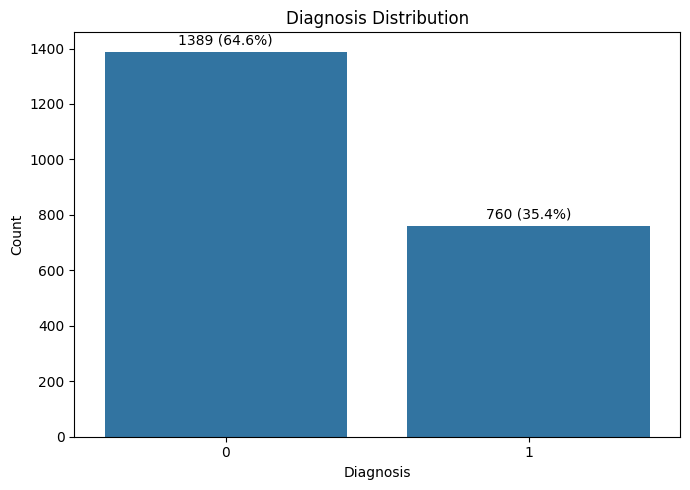

In [ ]:
# Plot the Diagnosis counts with percentages.

import matplotlib.pyplot as plt
import seaborn as sns

# Counts
diagnosis_counts = y.value_counts().sort_index()

# Percentages
diagnosis_percent = y.value_counts(normalize=True).sort_index() * 100

print("Diagnosis counts:")
display(diagnosis_counts)

print("\nDiagnosis percentages:")
display(diagnosis_percent.round(2))

plt.figure(figsize=(7, 5))

ax = sns.countplot(
    x=y,
    order=sorted(y.unique())
)

# x=y means the values we have in y make it in x axis so we can read the counts 1 and 0
# countplot in seaborn will drow a bar chart
plt.title("Diagnosis Distribution")
plt.xlabel("Diagnosis")
plt.ylabel("Count")

# Add percentage labels
total = len(y)

# prent percentage for each label
for container in ax.containers:
    labels = []
    for bar in container:
        count = bar.get_height()
        percentage = count / total * 100
        labels.append(f"{int(count)} ({percentage:.1f}%)")

    ax.bar_label(container, labels=labels, padding=3)

plt.tight_layout()
plt.show()

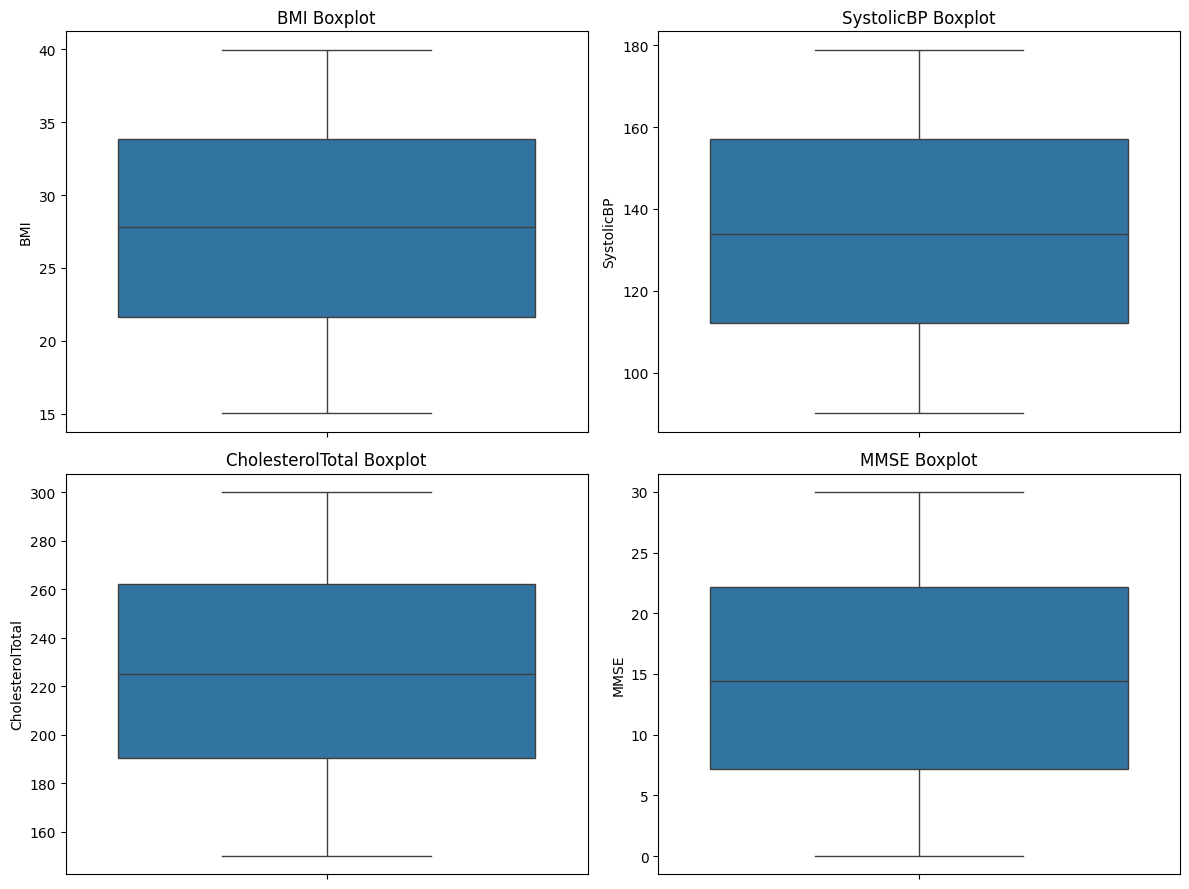

In [ ]:
# Create a 2 × 2 boxplot grid for BMI, SystolicBP, CholesterolTotal, and MMSE.

boxplot_features = [
    "BMI",
    "SystolicBP",
    "CholesterolTotal",
    "MMSE"
]
#subplots(2, 2) -> create 4 areas for plots
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# zip will create one ax for each feature
for ax, feature in zip(axes.flatten(), boxplot_features):
    sns.boxplot(
        y=df[feature],
        ax=ax
    )
    ax.set_title(f"{feature} Boxplot")
    ax.set_ylabel(feature)

plt.tight_layout()
plt.show()

In [ ]:
# Use the IQR rule to count potential outliers.
# Do not delete outliers automatically.

def count_iqr_outliers(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

# will search for each instance that is less than lower or grater than upper this will add it to data array
    outliers = data[
        (data[column] < lower_bound) |
        (data[column] > upper_bound)
    ]

    return {
        "Feature": column,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": len(outliers),
        "Outlier Percentage": len(outliers) / len(data) * 100
    }

#takes the function count_iqr_outliers and runs it for all the features in boxplot_features
outlier_results = pd.DataFrame([
    count_iqr_outliers(df, feature)
    for feature in boxplot_features
])

display(outlier_results)

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,BMI,21.611408,33.869778,12.258370,3.223853,52.257332,0,0.0
1,SystolicBP,112.000000,157.000000,45.000000,44.500000,224.500000,0,0.0
2,CholesterolTotal,190.252963,262.031657,71.778694,82.584923,369.699697,0,0.0
3,MMSE,7.167602,22.161028,14.993426,-15.322536,44.651166,0,0.0


In [ ]:
# Use an 80/20 stratified split with random_state=42.

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (1719, 32)
X_test: (430, 32)
y_train: (1719,)
y_test: (430,)


In [ ]:
# Standardize the 15 features with more than 10 unique values, one-hot encode Ethnicity, and pass binary and ordinal fields through.

# Features with more than 10 unique values
high_cardinality_features = [
    col for col in X.columns
    if X[col].nunique() > 10
]

# Features with 10 or fewer unique values
low_cardinality_features = [
    col for col in X.columns
    if X[col].nunique() <= 10
]

print("Features with >10 unique values:")
display(high_cardinality_features)

print("\nFeatures with <=10 unique values:")
display(low_cardinality_features)

Features with >10 unique values:


['Age',
 'BMI',
 'AlcoholConsumption',
 'PhysicalActivity',
 'DietQuality',
 'SleepQuality',
 'SystolicBP',
 'DiastolicBP',
 'CholesterolTotal',
 'CholesterolLDL',
 'CholesterolHDL',
 'CholesterolTriglycerides',
 'MMSE',
 'FunctionalAssessment',
 'ADL']


Features with <=10 unique values:


['Gender',
 'Ethnicity',
 'EducationLevel',
 'Smoking',
 'FamilyHistoryAlzheimers',
 'CardiovascularDisease',
 'Diabetes',
 'Depression',
 'HeadInjury',
 'Hypertension',
 'MemoryComplaints',
 'BehavioralProblems',
 'Confusion',
 'Disorientation',
 'PersonalityChanges',
 'DifficultyCompletingTasks',
 'Forgetfulness']

In [ ]:
# Standardized numerical features

numeric_features = [
    col for col in X.columns
    if X[col].nunique() > 10
]

# One-hot categorical feature

categorical_features = ["Ethnicity"]

# Binary and ordinal features

passthrough_features = [
    col for col in X.columns
    if col not in numeric_features + categorical_features
]

print("Number of numerical features:", len(numeric_features))
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

print("\nPassthrough features:")
print(passthrough_features)

print("\nTotal original features:", X.shape[1])

Number of numerical features: 15
['Age', 'BMI', 'AlcoholConsumption', 'PhysicalActivity', 'DietQuality', 'SleepQuality', 'SystolicBP', 'DiastolicBP', 'CholesterolTotal', 'CholesterolLDL', 'CholesterolHDL', 'CholesterolTriglycerides', 'MMSE', 'FunctionalAssessment', 'ADL']

Categorical features:
['Ethnicity']

Passthrough features:
['Gender', 'EducationLevel', 'Smoking', 'FamilyHistoryAlzheimers', 'CardiovascularDisease', 'Diabetes', 'Depression', 'HeadInjury', 'Hypertension', 'MemoryComplaints', 'BehavioralProblems', 'Confusion', 'Disorientation', 'PersonalityChanges', 'DifficultyCompletingTasks', 'Forgetfulness']

Total original features: 32


In [ ]:
# Fit on X_train. Transform X_train and X_test.

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

#ColumnTransformer allow us to apply different methods for each column using one function
# array of transsformers will hold all the methods we want to apply
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(
            # if there is new Ethnicity appeared in test data just ignore it
            handle_unknown="ignore",
            sparse_output=False
        ),
         categorical_features
         )
    ],
    remainder="passthrough"
)

X_train_processed = preprocessor.fit_transform(X_train)

# No fit function with X_test to avoid data leakage (when the model see the tested data which must be unseen to test the model)
X_test_processed = preprocessor.transform(X_test)

In [ ]:
# Confirm processed shapes are 1,719 × 35 and 430 × 35.

print("Processed X_train shape:", X_train_processed.shape)
print("Processed X_test shape:", X_test_processed.shape)

Processed X_train shape: (1719, 35)
Processed X_test shape: (430, 35)


In [ ]:
# inspect the final feature names

feature_names = preprocessor.get_feature_names_out()

print("Number of processed features:", len(feature_names))

display(pd.DataFrame({
    "Processed Feature": feature_names
}))

Number of processed features: 35


,Processed Feature
0,num__Age
1,num__BMI
2,num__AlcoholConsumption
3,num__PhysicalActivity
4,num__DietQuality
5,num__SleepQuality
6,num__SystolicBP
7,num__DiastolicBP
8,num__CholesterolTotal
9,num__CholesterolLDL


In [ ]:
# Make two scatterplots of MMSE versus CholesterolTotal: one in raw training units and one after training-only standardization.  Color points by Diagnosis.

visual_scaler = StandardScaler()

X_train_two = X_train[["MMSE", "CholesterolTotal"]].copy()

X_train_two_scaled = visual_scaler.fit_transform(X_train_two)

X_train_two_scaled = pd.DataFrame(
    X_train_two_scaled,
    columns=["MMSE", "CholesterolTotal"],
    index=X_train.index
)

# Add Diagnosis for plotting
raw_plot = X_train_two.copy()
raw_plot["Diagnosis"] = y_train

scaled_plot = X_train_two_scaled.copy()
scaled_plot["Diagnosis"] = y_train

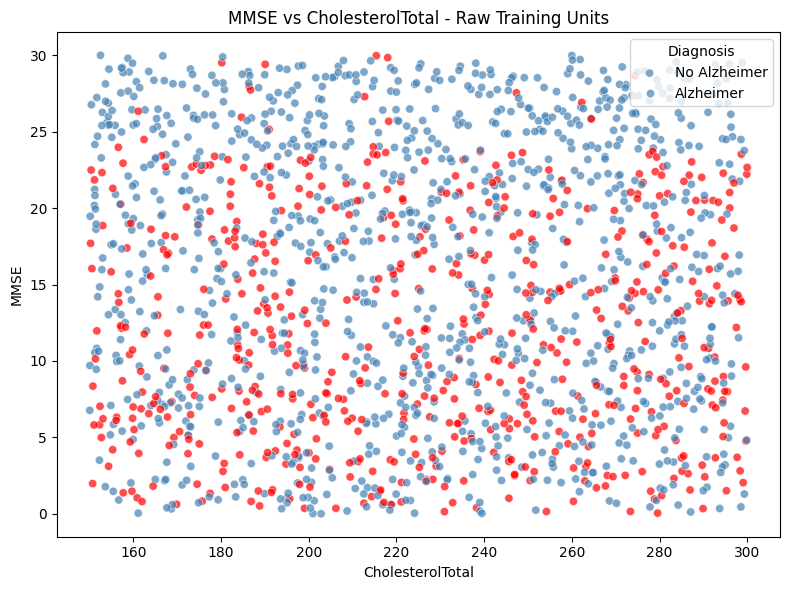

In [ ]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=raw_plot,
    x="CholesterolTotal",
    y="MMSE",
    hue="Diagnosis",
    palette={0: "steelblue", 1: "red"},
    alpha=0.7
)

plt.title("MMSE vs CholesterolTotal - Raw Training Units")
plt.xlabel("CholesterolTotal")
plt.ylabel("MMSE")
plt.legend(title="Diagnosis", labels=["No Alzheimer", "Alzheimer"])
plt.tight_layout()
plt.show()

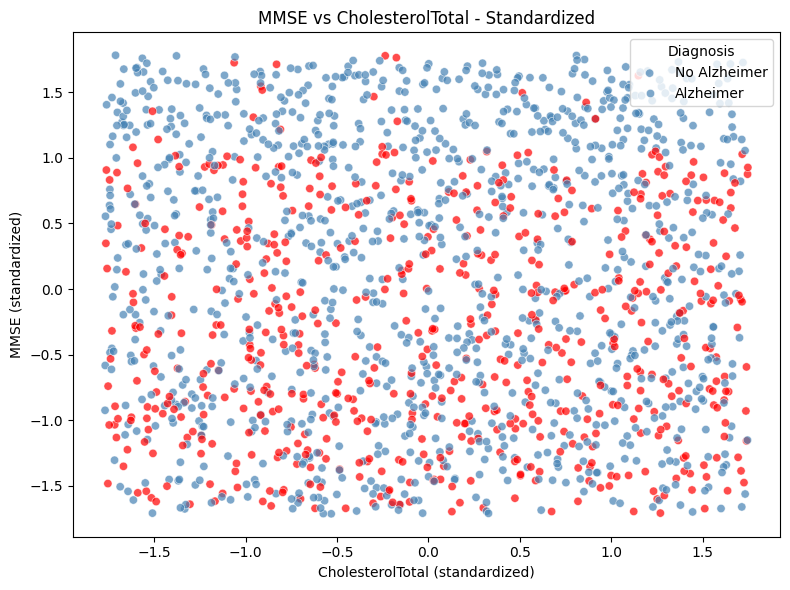

In [ ]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=scaled_plot,
    x="CholesterolTotal",
    y="MMSE",
    hue="Diagnosis",
    palette={0: "steelblue", 1: "red"},
    alpha=0.7
)

plt.title("MMSE vs CholesterolTotal - Standardized")
plt.xlabel("CholesterolTotal (standardized)")
plt.ylabel("MMSE (standardized)")
plt.legend(title="Diagnosis", labels=["No Alzheimer", "Alzheimer"])
plt.tight_layout()
plt.show()

In [ ]:
# Convert the transformed arrays to labeled DataFrames using get_feature_names_out().
#-------------------------------------- stopped here -------------------------------

feature_names = preprocessor.get_feature_names_out()

X_train_processed_df = pd.DataFrame(
    X_train_processed,
    columns=feature_names,
    index=X_train.index
)

X_test_processed_df = pd.DataFrame(
    X_test_processed,
    columns=feature_names,
    index=X_test.index
)

print("Training data:")
display(X_train_processed_df.head())

print("Training shape:", X_train_processed_df.shape)
print("Test shape:", X_test_processed_df.shape)

Training data:


,num__Age,num__BMI,num__AlcoholConsumption,num__PhysicalActivity,num__DietQuality,num__SleepQuality,num__SystolicBP,num__DiastolicBP,num__CholesterolTotal,num__CholesterolLDL,...,remainder__Depression,remainder__HeadInjury,remainder__Hypertension,remainder__MemoryComplaints,remainder__BehavioralProblems,remainder__Confusion,remainder__Disorientation,remainder__PersonalityChanges,remainder__DifficultyCompletingTasks,remainder__Forgetfulness
780,1.230721,0.065466,1.478214,0.571099,-1.276449,1.457443,0.195308,-0.234958,0.059480,-1.656832,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1341,-1.430841,0.070065,-0.407432,-1.050032,0.340303,-1.135747,1.622491,1.200748,1.498922,1.190810,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
820,0.010838,-0.316941,-0.288334,1.628134,-1.119152,0.512803,-0.498997,1.545317,0.019782,0.414247,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
857,1.563416,-0.567289,-1.418146,-1.257326,1.279730,1.255038,1.391056,-1.096381,-0.159480,-0.970426,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0
593,0.121737,1.533521,-0.190409,1.188813,0.982253,-0.632116,-0.614714,-0.522099,-1.634594,-0.220092,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


Training shape: (1719, 35)
Test shape: (430, 35)


In [ ]:
# Train KNeighborsClassifier(n_neighbors=5) and predict the untouched test set.

from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train_processed_df, y_train)

# Predict untouched test set
y_pred = knn.predict(X_test_processed_df)

print("Predictions generated:", len(y_pred))

Predictions generated: 430


In [ ]:
# Report accuracy, balanced accuracy, Alzheimer precision, Alzheimer recall, and macro F1.

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

accuracy = accuracy_score(y_test, y_pred)

balanced_acc = balanced_accuracy_score(y_test, y_pred)

# For class 1 = Alzheimer
alzheimer_precision = precision_score(
    y_test,
    y_pred,
    pos_label=1
)

alzheimer_recall = recall_score(
    y_test,
    y_pred,
    pos_label=1
)

macro_f1 = f1_score(
    y_test,
    y_pred,
    average="macro"
)

metrics = {
    "Accuracy": accuracy,
    "Balanced Accuracy": balanced_acc,
    "Alzheimer Precision": alzheimer_precision,
    "Alzheimer Recall": alzheimer_recall,
    "Macro F1": macro_f1
}

metrics_df = pd.DataFrame(
    metrics.items(),
    columns=["Metric", "Score"]
)

display(metrics_df)

,Metric,Score
0,Accuracy,0.741860
1,Balanced Accuracy,0.687050
2,Alzheimer Precision,0.684685
3,Alzheimer Recall,0.500000
4,Macro F1,0.696009


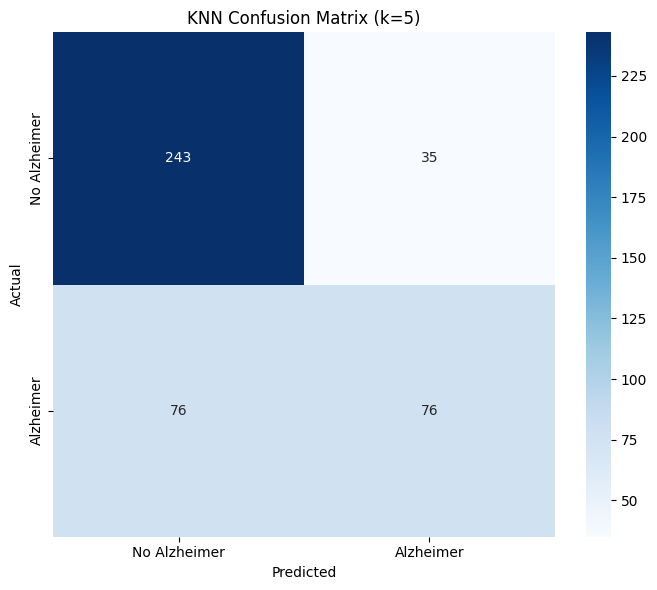

In [ ]:
# Create a confusion matrix labeled No Alzheimer and Alzheimer.

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Alzheimer", "Alzheimer"],
    yticklabels=["No Alzheimer", "Alzheimer"]
)

plt.title("KNN Confusion Matrix (k=5)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

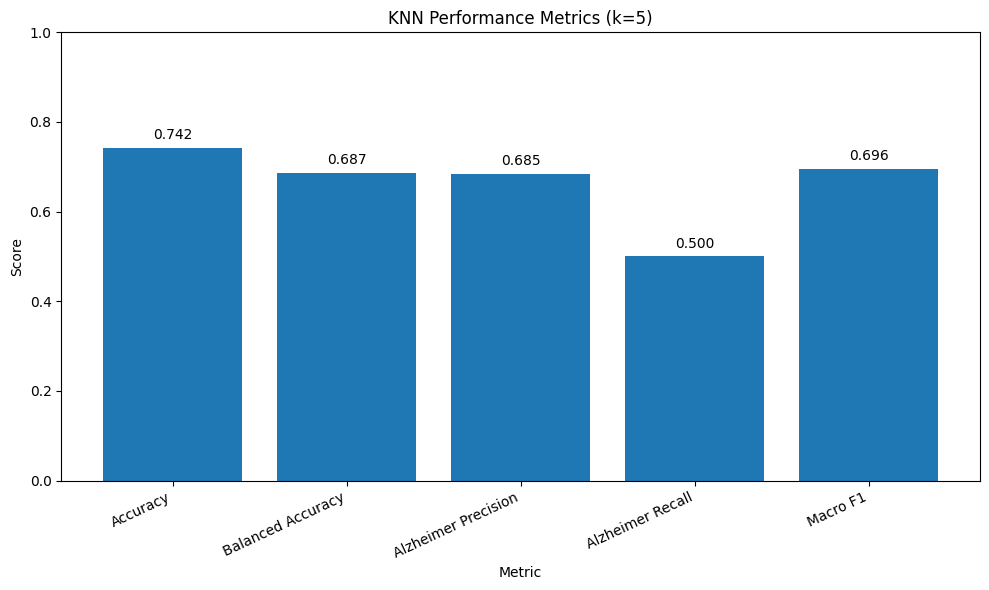

In [ ]:
# Create a 0-to-1 bar chart comparing all five metrics.

plt.figure(figsize=(10, 6))

bars = plt.bar(
    metrics_df["Metric"],
    metrics_df["Score"]
)

plt.ylim(0, 1)
plt.ylabel("Score")
plt.xlabel("Metric")
plt.title("KNN Performance Metrics (k=5)")
plt.xticks(rotation=25, ha="right")

# Add values above bars
for bar, value in zip(bars, metrics_df["Score"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.02,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

In [ ]:
# Repeat training for k = 3, 5, 7, 9, 11, 15.

k_values = [3, 5, 7, 9, 11, 15]

k_results = []

for k in k_values:

    knn_k = KNeighborsClassifier(n_neighbors=k)

    knn_k.fit(X_train_processed_df, y_train)

    pred_k = knn_k.predict(X_test_processed_df)

    balanced_acc_k = balanced_accuracy_score(
        y_test,
        pred_k
    )

    recall_k = recall_score(
        y_test,
        pred_k,
        pos_label=1
    )

    k_results.append({
        "k": k,
        "Balanced Accuracy": balanced_acc_k,
        "Alzheimer Recall": recall_k
    })

k_results_df = pd.DataFrame(k_results)

display(k_results_df)

,k,Balanced Accuracy,Alzheimer Recall
0,3,0.664284,0.486842
1,5,0.687050,0.500000
2,7,0.711307,0.519737
3,9,0.690387,0.467105
4,11,0.709556,0.480263
5,15,0.709556,0.480263


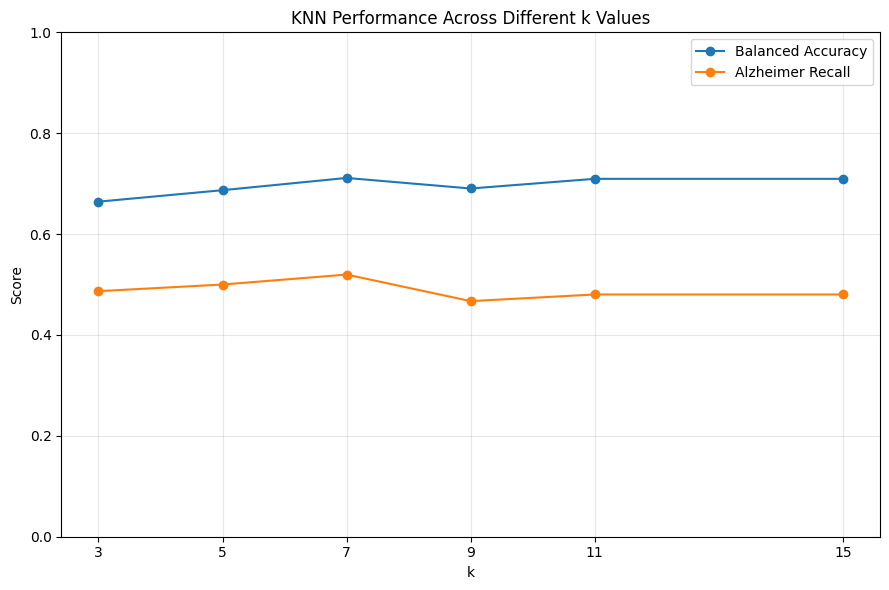

In [ ]:
# Plot balanced accuracy and Alzheimer recall against k.

plt.figure(figsize=(9, 6))

plt.plot(
    k_results_df["k"],
    k_results_df["Balanced Accuracy"],
    marker="o",
    label="Balanced Accuracy"
)

plt.plot(
    k_results_df["k"],
    k_results_df["Alzheimer Recall"],
    marker="o",
    label="Alzheimer Recall"
)

plt.xticks(k_values)
plt.ylim(0, 1)
plt.xlabel("k")
plt.ylabel("Score")
plt.title("KNN Performance Across Different k Values")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# Select one k and justify the trade-off.

best_k_balanced = k_results_df.loc[
    k_results_df["Balanced Accuracy"].idxmax(),
    "k"
]

best_balanced_score = k_results_df.loc[
    k_results_df["Balanced Accuracy"].idxmax(),
    "Balanced Accuracy"
]

print(
    f"Best k based on balanced accuracy: "
    f"{best_k_balanced} ({best_balanced_score:.3f})"
)

best_k_recall = k_results_df.loc[
    k_results_df["Alzheimer Recall"].idxmax(),
    "k"
]

best_recall_score = k_results_df.loc[
    k_results_df["Alzheimer Recall"].idxmax(),
    "Alzheimer Recall"
]

print(
    f"Best k based on Alzheimer recall: "
    f"{best_k_recall} ({best_recall_score:.3f})"
)

Best k based on balanced accuracy: 7 (0.711)
Best k based on Alzheimer recall: 7 (0.520)


In [ ]:
# For one test patient, use kneighbors() to display the five distances and class votes.

patient_position = 0

query = X_test_processed_df.iloc[
    [patient_position]
]

actual_label = y_test.iloc[patient_position]

# Use your selected k, or 5 for the baseline
selected_k = 5

knn_explain = KNeighborsClassifier(
    n_neighbors=selected_k
)

knn_explain.fit(
    X_train_processed_df,
    y_train
)

prediction = knn_explain.predict(query)[0]

print("Actual diagnosis:", actual_label)
print("Predicted diagnosis:", prediction)

distances, indices = knn_explain.kneighbors(
    query,
    n_neighbors=5
)

neighbor_indices = indices[0]
neighbor_distances = distances[0]

neighbor_labels = y_train.iloc[
    neighbor_indices
].values

neighbors_df = pd.DataFrame({
    "Neighbor": range(1, 6),
    "Training Index": X_train_processed_df.index[neighbor_indices],
    "Distance": neighbor_distances,
    "Diagnosis": neighbor_labels
})

display(neighbors_df)

vote_counts = pd.Series(
    neighbor_labels
).value_counts()

no_alzheimer_votes = vote_counts.get(0, 0)
alzheimer_votes = vote_counts.get(1, 0)

print("Votes among 5 nearest neighbors:")
print(f"No Alzheimer: {no_alzheimer_votes}")
print(f"Alzheimer: {alzheimer_votes}")

Actual diagnosis: 1
Predicted diagnosis: 1


,Neighbor,Training Index,Distance,Diagnosis
0,1,511,3.901263,0
1,2,943,4.025916,1
2,3,265,4.062663,1
3,4,417,4.071844,1
4,5,360,4.145764,1


Votes among 5 nearest neighbors:
No Alzheimer: 1
Alzheimer: 4


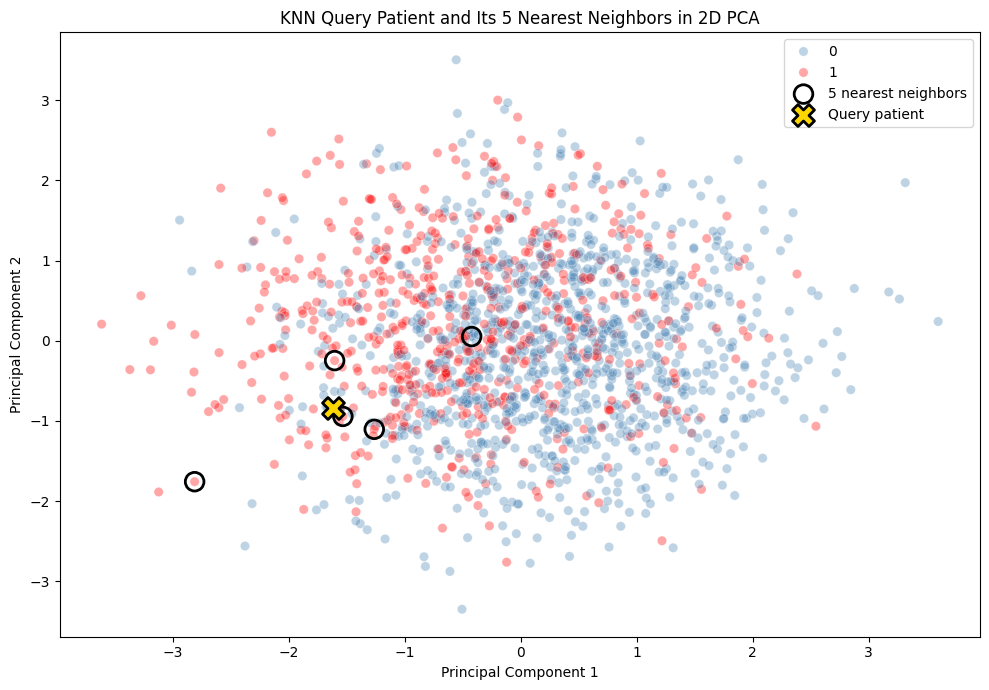

In [ ]:
# Optional: mark the query and its exact neighbors on a 2D PCA plot.
# PCA is for display only; neighbor search must use all processed features.

from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)

X_train_pca = pca.fit_transform(X_train_processed_df)

query_pca = pca.transform(query)

neighbor_pca = X_train_pca[neighbor_indices]

pca_df = pd.DataFrame({
    "PC1": X_train_pca[:, 0],
    "PC2": X_train_pca[:, 1],
    "Diagnosis": y_train.values
})

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Diagnosis",
    palette={0: "steelblue", 1: "red"},
    alpha=0.35,
    s=45
)

plt.scatter(
    neighbor_pca[:, 0],
    neighbor_pca[:, 1],
    facecolors="none",
    edgecolors="black",
    s=180,
    linewidths=2,
    label="5 nearest neighbors"
)

plt.scatter(
    query_pca[0, 0],
    query_pca[0, 1],
    marker="X",
    color="gold",
    edgecolors="black",
    s=250,
    linewidths=2,
    label="Query patient"
)

plt.title("KNN Query Patient and Its 5 Nearest Neighbors in 2D PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.tight_layout()
plt.show()